# 1. Exploração dos dados

[índice](README.pt-BR.md) · [Qualidade dos dados e limpeza](02_data_quality.ipynb) →

Carregamento do SVHN, divisão estratificada em treino e validação, distribuição das classes e exemplos de imagens. O código compartilhado por todos os notebooks está em [`svhn_utils.py`](svhn_utils.py).

## Dados

Uso o `torchvision.datasets.SVHN` com os splits `train` (73.257 imagens) e `test`
(26.032 imagens). Divido o `train` de forma estratificada, mantendo a proporção de cada
dígito, em 90% para treino e 10% para validação. A semente é fixa, então todos os
experimentos usam exatamente a mesma divisão.

- A **validação** acompanha o treino, controla o *early stopping* e serve para escolher o modelo.
- O **teste** só estima o desempenho final e não entra em nenhuma decisão.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import torch

from svhn_utils import figures_dir, get_device, load_data
FIG_DIR = figures_dir("01_data_exploration")   # figuras deste notebook em outputs/figures/01_data_exploration/

print("PyTorch", torch.__version__, "| device:", get_device())
data, split = load_data()
for k, (X, y) in data.items():
    print(f"{k:5s}: {tuple(X.shape)}")

PyTorch 2.14.1 | device: mps


train: (65931, 3, 32, 32)
val  : (7326, 3, 32, 32)
test : (26032, 3, 32, 32)


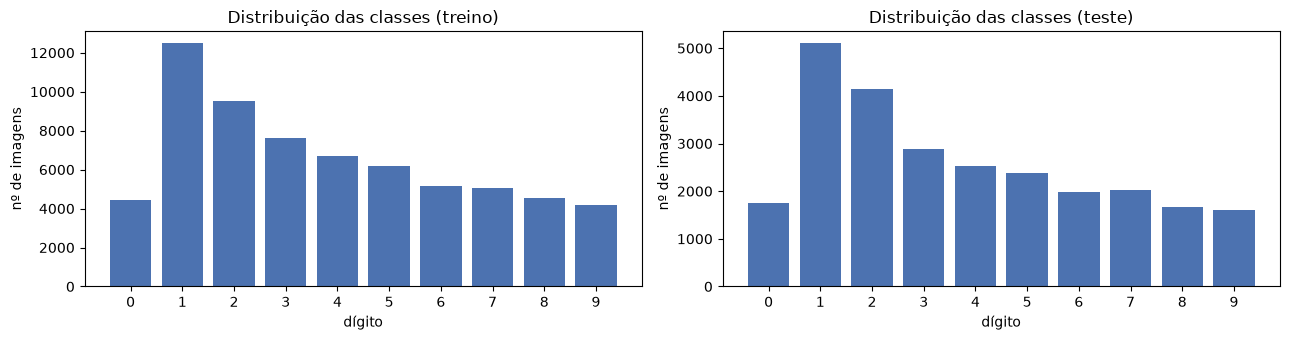

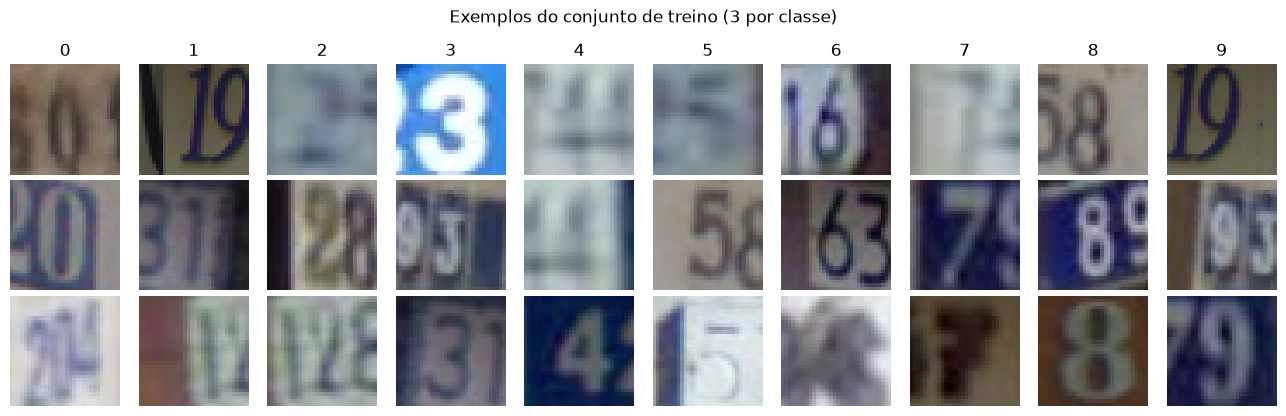

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for ax, (k, (_, y)) in zip(axes, [("treino", data["train"]), ("teste", data["test"])]):
    counts = torch.bincount(y, minlength=10).numpy()
    ax.bar(range(10), counts, color="#4C72B0")
    ax.set_xticks(range(10)); ax.set_title(f"Distribuição das classes ({k})")
    ax.set_xlabel("dígito"); ax.set_ylabel("nº de imagens")
plt.tight_layout(); plt.savefig(FIG_DIR / "class_distribution.png", dpi=150); plt.show()

fig, axes = plt.subplots(3, 10, figsize=(13, 4.2))
Xtr, ytr = data["train"]
for c in range(10):
    idx = (ytr == c).nonzero().squeeze(1)[:3]
    for r, i in enumerate(idx):
        axes[r, c].imshow(Xtr[i].permute(1, 2, 0).numpy()); axes[r, c].axis("off")
    axes[0, c].set_title(str(c))
plt.suptitle("Exemplos do conjunto de treino (3 por classe)")
plt.tight_layout(); plt.savefig(FIG_DIR / "samples.png", dpi=150); plt.show()

O dataset é desbalanceado, com os dígitos 1 e 2 bem mais frequentes que os demais. As imagens
também variam muito em cor, iluminação e fundo, e é comum aparecerem dígitos vizinhos nas
bordas. O rótulo é sempre o dígito do centro.

In [3]:
counts = pd.DataFrame({k: torch.bincount(y, minlength=10).numpy() for k, (_, y) in data.items()})
counts.index.name = "dígito"
counts["% do treino"] = (counts["train"] / counts["train"].sum() * 100).round(1)
counts

,train,val,test,% do treino
dígito,,,,
0,4453,495,1744,6.8
1,12475,1386,5099,18.9
2,9527,1058,4149,14.4
3,7647,850,2882,11.6
4,6712,746,2523,10.2
5,6194,688,2384,9.4
6,5154,573,1977,7.8
7,5035,560,2019,7.6
8,4541,504,1660,6.9
